In [2]:
import numpy as np
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from xgboost import XGBRegressor
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import ConvLSTM2D, Dense, Flatten, Dropout
from tensorflow.keras.optimizers import Adam

In [3]:
df = pd.read_csv('gold_2007_to_present.csv')
# Remove 2nd and 3rd rows (Python uses zero-based indexing)
df = df.drop([1, 2]).reset_index(drop=True)

# Optional: verify
print(df.head(5))


        Price              Close               High                Low  \
0      Ticker               GC=F               GC=F               GC=F   
1  2007-01-03  627.0999755859375  640.4000244140625              628.5   
2  2007-01-04  623.9000244140625              624.5              624.5   
3  2007-01-05  604.9000244140625  623.7000122070312  617.2999877929688   
4  2007-01-08              607.5              607.5              607.5   

                Open Volume  
0               GC=F   GC=F  
1  640.4000244140625     38  
2              624.5      4  
3  623.7000122070312    531  
4              607.5   1000  


In [4]:
# Assuming your DataFrame is named df
df = df.drop(index=0).reset_index(drop=True)

# Optional: confirm it worked
print(df.head())


        Price              Close               High                Low  \
0  2007-01-03  627.0999755859375  640.4000244140625              628.5   
1  2007-01-04  623.9000244140625              624.5              624.5   
2  2007-01-05  604.9000244140625  623.7000122070312  617.2999877929688   
3  2007-01-08              607.5              607.5              607.5   
4  2007-01-09  613.0999755859375              607.0              607.0   

                Open Volume  
0  640.4000244140625     38  
1              624.5      4  
2  623.7000122070312    531  
3              607.5   1000  
4              607.0      2  


In [5]:
df.columns = ['Date', 'Open', 'High', 'Low', 'Close', 'Volume']  # rename manually

In [6]:
for col in df.columns:
    if col != 'Date':
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Optional: fill missing values created by coercion
df = df.fillna(method='ffill').fillna(method='bfill')

# Confirm that everything is now numeric
print(df.dtypes)

Date       object
Open      float64
High      float64
Low       float64
Close     float64
Volume      int64
dtype: object


C:\Users\ASUS\AppData\Local\Temp\ipykernel_20416\1277827392.py:6: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='ffill').fillna(method='bfill')


Epoch 1/25


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


267/267 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 879727.9375 - val_loss: 9138562.0000
Epoch 2/25
267/267 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 28963.9062 - val_loss: 3352314.5000
Epoch 3/25
267/267 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 14756.8164 - val_loss: 2381290.5000
Epoch 4/25
267/267 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 11003.1230 - val_loss: 1973425.1250
Epoch 5/25
267/267 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 9175.7764 - val_loss: 1561957.7500
Epoch 6/25
267/267 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 8243.1729 - val_loss: 1013224.7500
Epoch 7/25
267/267 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 7695.4321 - val_loss: 582326.5000
Epoch 8/25
267/267 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 7120.8149 - val_loss: 634656.5000
Epoch 9/25
267/267 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 6564.8315 - val_loss: 358396.5938
Epoch 10/25
267/267 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 6053.8901 - val_loss: 416343.3125
Epoch 11/25
267/267 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss

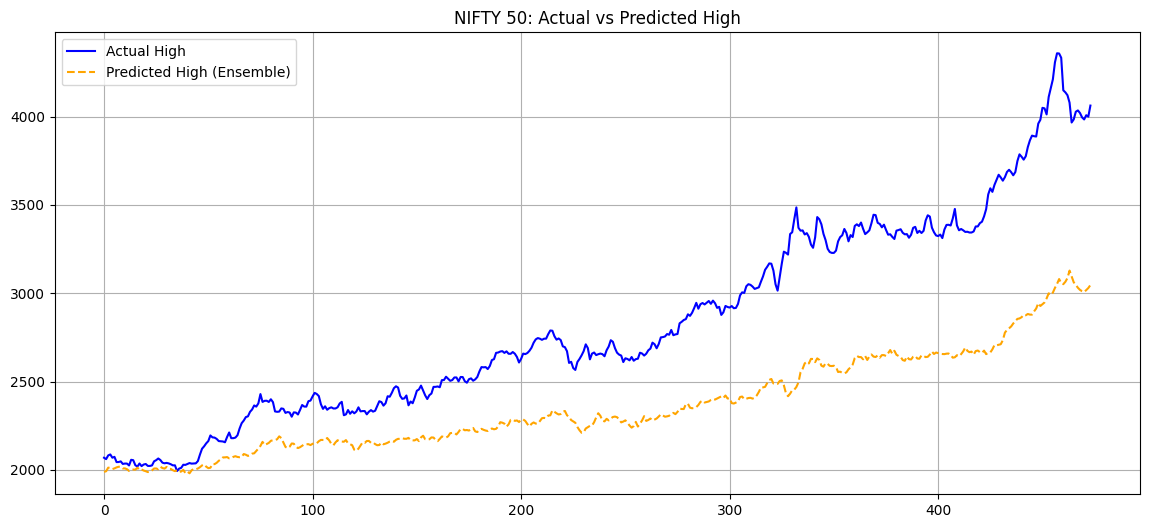

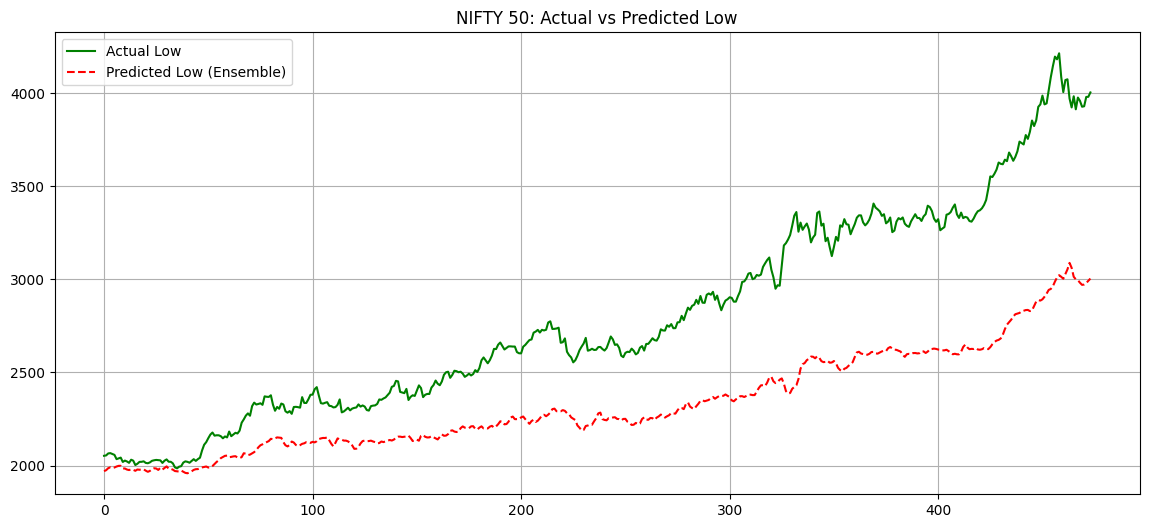

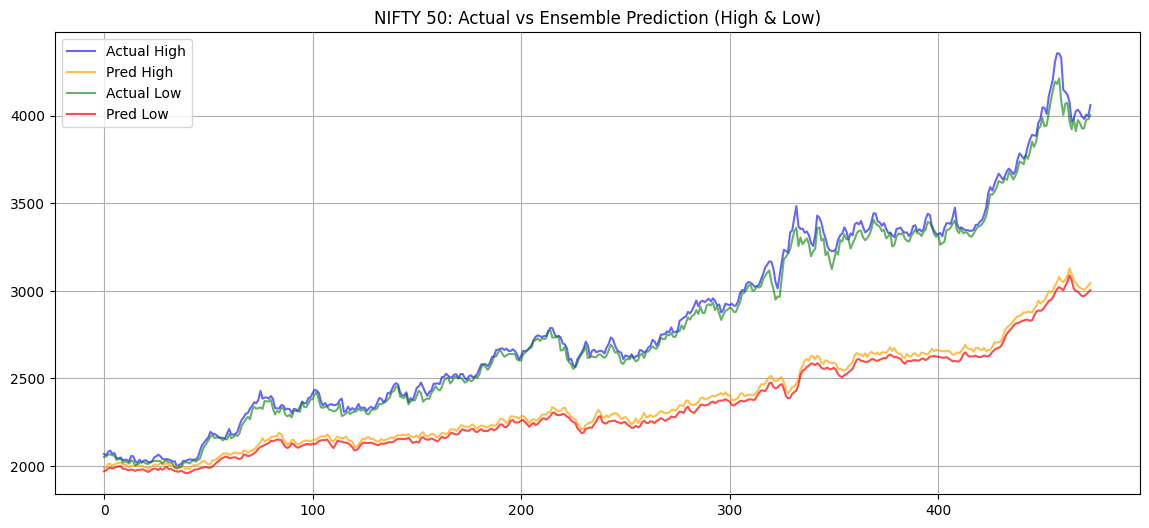

In [8]:
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

# Create lag features
for lag in range(1, 6):
    df[f'Open_lag_{lag}'] = df['Open'].shift(lag)
    df[f'Close_lag_{lag}'] = df['Close'].shift(lag)
    df[f'High_lag_{lag}'] = df['High'].shift(lag)
    df[f'Low_lag_{lag}'] = df['Low'].shift(lag)

# Rolling mean and std
df['MA_5'] = df['Close'].rolling(window=5).mean()
df['STD_5'] = df['Close'].rolling(window=5).std()

# Date-time features
df['DayOfWeek'] = df['Date'].dt.dayofweek
df['Month'] = df['Date'].dt.month

# Drop NaN
df = df.dropna().reset_index(drop=True)

# ------------------------------------------------------------
# STEP 2: DEFINE FEATURES & TARGETS
# ------------------------------------------------------------
features = [col for col in df.columns if col not in ['Date', 'High', 'Low']]
X = df[features]
y_high = df['High']
y_low = df['Low']

# Train-Test Split (no shuffle, to preserve time order)
split_ratio = 0.9
split_idx = int(len(df) * split_ratio)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_high_train, y_high_test = y_high.iloc[:split_idx], y_high.iloc[split_idx:]
y_low_train, y_low_test = y_low.iloc[:split_idx], y_low.iloc[split_idx:]

# Scale
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ------------------------------------------------------------
# STEP 3: XGBOOST MODELS (TABULAR)
# ------------------------------------------------------------
xgb_high = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6)
xgb_low = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6)

xgb_high.fit(X_train_scaled, y_high_train)
xgb_low.fit(X_train_scaled, y_low_train)

pred_high_xgb = xgb_high.predict(X_test_scaled)
pred_low_xgb = xgb_low.predict(X_test_scaled)

# ------------------------------------------------------------
# STEP 4: ConvLSTM MODEL (SEQUENTIAL)
# ------------------------------------------------------------
def create_sequences(X, y_high, y_low, seq_len=5):
    X_seq, yh_seq, yl_seq = [], [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        yh_seq.append(y_high[i])
        yl_seq.append(y_low[i])
    return np.array(X_seq), np.array(yh_seq), np.array(yl_seq)

seq_len = 5
X_scaled_full = scaler.fit_transform(X)
X_seq, y_high_seq, y_low_seq = create_sequences(X_scaled_full, y_high.values, y_low.values, seq_len)

split_idx_seq = int(len(X_seq) * split_ratio)
X_train_seq, X_test_seq = X_seq[:split_idx_seq], X_seq[split_idx_seq:]
y_high_train_seq, y_high_test_seq = y_high_seq[:split_idx_seq], y_high_seq[split_idx_seq:]
y_low_train_seq, y_low_test_seq = y_low_seq[:split_idx_seq], y_low_seq[split_idx_seq:]

# Reshape for ConvLSTM: [samples, timesteps, rows, cols, features]
X_train_seq = X_train_seq.reshape((X_train_seq.shape[0], seq_len, 1, 1, X_train_seq.shape[2]))
X_test_seq = X_test_seq.reshape((X_test_seq.shape[0], seq_len, 1, 1, X_test_seq.shape[2]))

model = Sequential([
    ConvLSTM2D(32, (1,1), activation='relu', input_shape=(seq_len, 1, 1, X_train_seq.shape[-1]), return_sequences=True),
    Dropout(0.2),
    ConvLSTM2D(16, (1,1), activation='relu'),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(2)
])
model.compile(optimizer=Adam(0.001), loss='mse')

y_train_seq_combined = np.column_stack((y_high_train_seq, y_low_train_seq))
y_test_seq_combined = np.column_stack((y_high_test_seq, y_low_test_seq))

history = model.fit(
    X_train_seq, y_train_seq_combined,
    epochs=25, batch_size=16, validation_data=(X_test_seq, y_test_seq_combined),
    verbose=1
)

pred_seq = model.predict(X_test_seq)
pred_high_conv, pred_low_conv = pred_seq[:,0], pred_seq[:,1]

# ------------------------------------------------------------
# STEP 5: ENSEMBLE (WEIGHTED AVERAGE)
# ------------------------------------------------------------
# Align sequence-based test predictions with tabular test indices
min_len = min(len(pred_high_conv), len(pred_high_xgb))
pred_high_ensemble = 0.6 * pred_high_conv[-min_len:] + 0.4 * pred_high_xgb[-min_len:]
pred_low_ensemble  = 0.6 * pred_low_conv[-min_len:]  + 0.4 * pred_low_xgb[-min_len:]

y_high_true = y_high_test.values[-min_len:]
y_low_true = y_low_test.values[-min_len:]

# ------------------------------------------------------------
# STEP 6: METRICS
# ------------------------------------------------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    print(f"\n📊 {label} Metrics:")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")
    print(f"MAPE : {mape:.2f}%")
    return mae, rmse, r2, mape

m_high = metrics(y_high_true, pred_high_ensemble, "High (Ensemble)")
m_low = metrics(y_low_true, pred_low_ensemble, "Low (Ensemble)")

# ------------------------------------------------------------
# STEP 7: VISUAL COMPARISONS
# ------------------------------------------------------------
plt.figure(figsize=(14,6))
plt.plot(y_high_true, label="Actual High", color='blue')
plt.plot(pred_high_ensemble, label="Predicted High (Ensemble)", color='orange', linestyle='--')
plt.title("NIFTY 50: Actual vs Predicted High")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(14,6))
plt.plot(y_low_true, label="Actual Low", color='green')
plt.plot(pred_low_ensemble, label="Predicted Low (Ensemble)", color='red', linestyle='--')
plt.title("NIFTY 50: Actual vs Predicted Low")
plt.legend()
plt.grid(True)
plt.show()

# Optional: plot combined
plt.figure(figsize=(14,6))
plt.plot(y_high_true, label="Actual High", color='blue', alpha=0.6)
plt.plot(pred_high_ensemble, label="Pred High", color='orange', alpha=0.7)
plt.plot(y_low_true, label="Actual Low", color='green', alpha=0.6)
plt.plot(pred_low_ensemble, label="Pred Low", color='red', alpha=0.7)
plt.title("NIFTY 50: Actual vs Ensemble Prediction (High & Low)")
plt.legend()
plt.grid(True)
plt.show()


📊 High (XGBoost) Metrics:
MAE  : 770.548
RMSE : 950.556
R²   : -1.822
MAPE : 24.50%

📊 Low (XGBoost) Metrics:
MAE  : 766.990
RMSE : 943.891
R²   : -1.924
MAPE : 24.71%


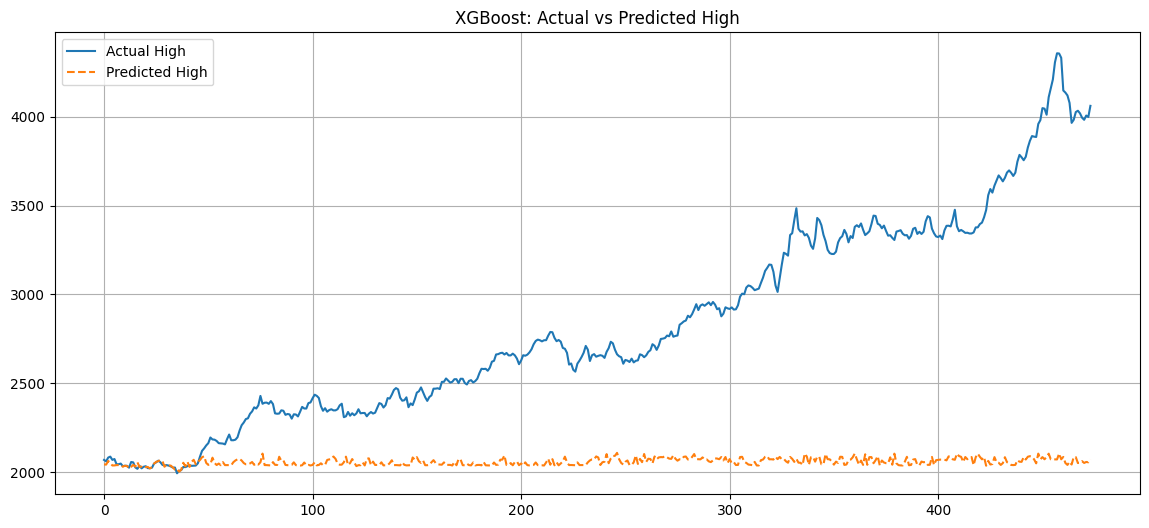

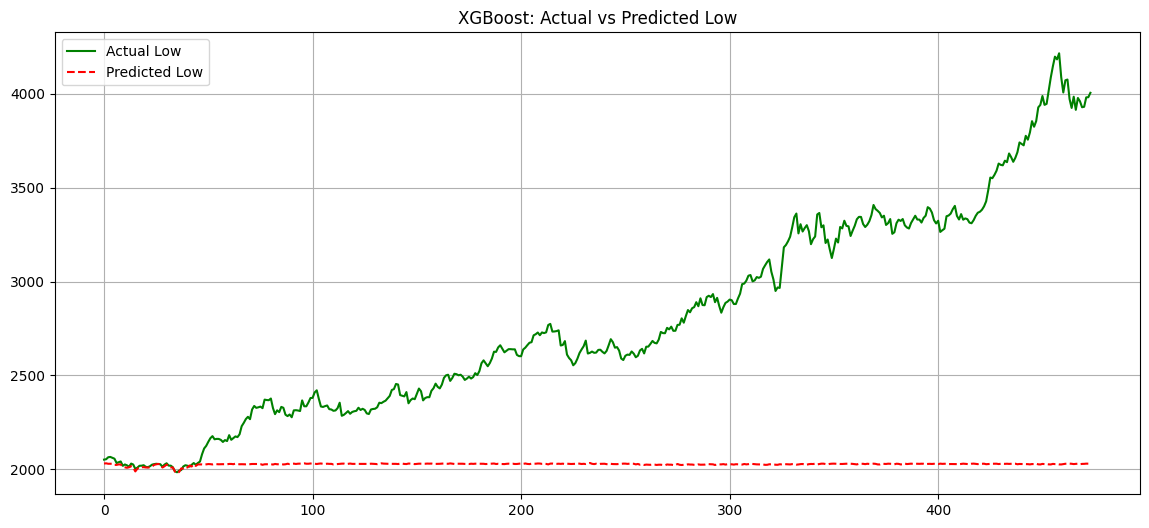

In [9]:
for lag in range(1,6):
    df[f'Open_lag_{lag}'] = df['Open'].shift(lag)
    df[f'Close_lag_{lag}'] = df['Close'].shift(lag)
    df[f'High_lag_{lag}'] = df['High'].shift(lag)
    df[f'Low_lag_{lag}'] = df['Low'].shift(lag)

# Drop NaNs
df = df.dropna().reset_index(drop=True)

# Features & target
features = [col for col in df.columns if col not in ['Date', 'High', 'Low']]
X = df[features]
y_high = df['High']
y_low = df['Low']

# Train-test split (no shuffle)
split_idx = int(len(df)*0.9)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_high_train, y_high_test = y_high.iloc[:split_idx], y_high.iloc[split_idx:]
y_low_train, y_low_test = y_low.iloc[:split_idx], y_low.iloc[split_idx:]

# Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ------------------ TRAIN XGBOOST ------------------
xgb_high = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6)
xgb_low = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6)

xgb_high.fit(X_train_scaled, y_high_train)
xgb_low.fit(X_train_scaled, y_low_train)

# Predict
pred_high = xgb_high.predict(X_test_scaled)
pred_low = xgb_low.predict(X_test_scaled)

# ------------------ METRICS ------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100
    print(f"\n📊 {label} Metrics:")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")
    print(f"MAPE : {mape:.2f}%")
    return mae, rmse, r2, mape

metrics(y_high_test, pred_high, "High (XGBoost)")
metrics(y_low_test, pred_low, "Low (XGBoost)")

# ------------------ PLOTS ------------------
plt.figure(figsize=(14,6))
plt.plot(y_high_test.values, label="Actual High")
plt.plot(pred_high, label="Predicted High", linestyle='--')
plt.title("XGBoost: Actual vs Predicted High")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(14,6))
plt.plot(y_low_test.values, label="Actual Low", color='green')
plt.plot(pred_low, label="Predicted Low", linestyle='--', color='red')
plt.title("XGBoost: Actual vs Predicted Low")
plt.legend(); plt.grid(True); plt.show()

In [10]:
from tensorflow.keras.layers import LSTM, Dense, Dropout

Epoch 1/25


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


266/266 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0556 - val_loss: 5.7303
Epoch 2/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0118 - val_loss: 1.9490
Epoch 3/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0098 - val_loss: 2.0390
Epoch 4/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0101 - val_loss: 0.5639
Epoch 5/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0093 - val_loss: 0.5214
Epoch 6/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0084 - val_loss: 0.0738
Epoch 7/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0077 - val_loss: 0.0155
Epoch 8/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0071 - val_loss: 0.0313
Epoch 9/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0074 - val_loss: 0.0354
Epoch 10/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0070 - val_loss: 0.0846
Epoch 11/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0072 - val_loss: 0.0186
Epoch 12/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.

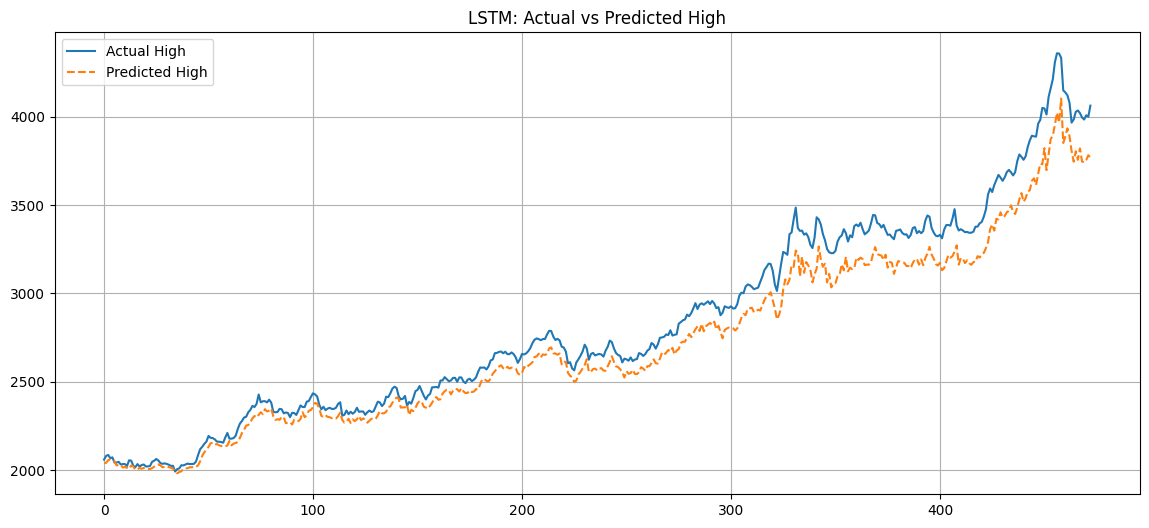

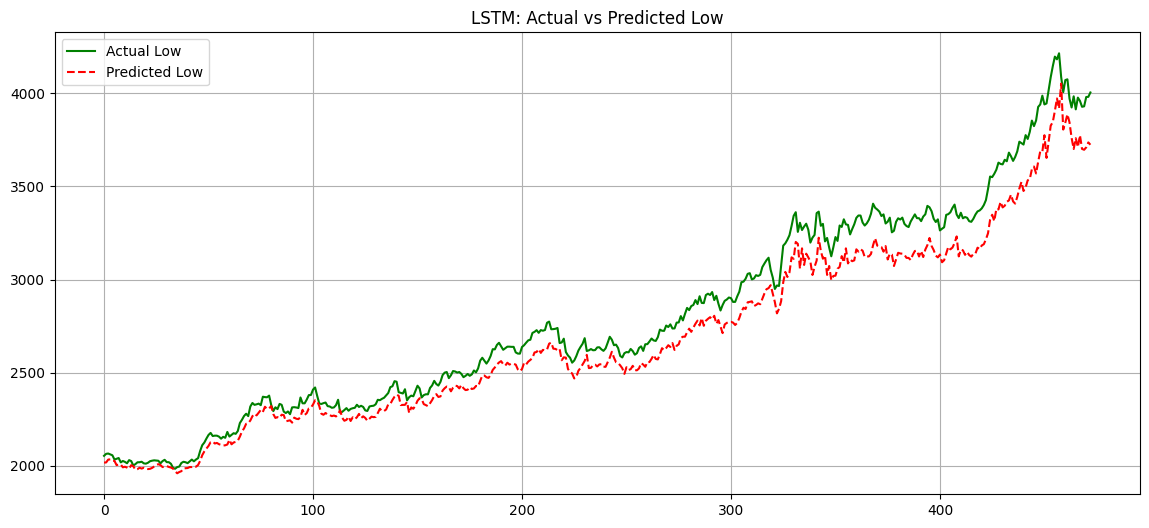

In [11]:
features = ['Open', 'Close', 'High', 'Low']
X = df[features].values
y_high = df['High'].values
y_low = df['Low'].values

# Scaling
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X)

scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(df[['High','Low']].values)

# ------------------ CREATE SEQUENCES ------------------
def create_seq(X, y, seq_len=5):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)

seq_len = 5
X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

# Train-test split
split_idx = int(len(X_seq)*0.9)
X_train, X_test = X_seq[:split_idx], X_seq[split_idx:]
y_train, y_test = y_seq[:split_idx], y_seq[split_idx:]

# ------------------ LSTM MODEL ------------------
model = Sequential([
    LSTM(50, activation='relu', input_shape=(seq_len, X_train.shape[2]), return_sequences=False),
    Dropout(0.2),
    Dense(2)
])
model.compile(optimizer='adam', loss='mse')

# Train
history = model.fit(X_train, y_train, epochs=25, batch_size=16, validation_data=(X_test, y_test), verbose=1)

# Predict
pred = model.predict(X_test)
pred_inv = scaler_y.inverse_transform(pred)
y_test_inv = scaler_y.inverse_transform(y_test)

pred_high, pred_low = pred_inv[:,0], pred_inv[:,1]
y_high_true, y_low_true = y_test_inv[:,0], y_test_inv[:,1]

# ------------------ METRICS ------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100
    print(f"\n📊 {label} Metrics:")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")
    print(f"MAPE : {mape:.2f}%")
    return mae, rmse, r2, mape

metrics(y_high_true, pred_high, "High (LSTM)")
metrics(y_low_true, pred_low, "Low (LSTM)")

# ------------------ PLOTS ------------------
plt.figure(figsize=(14,6))
plt.plot(y_high_true, label="Actual High")
plt.plot(pred_high, label="Predicted High", linestyle='--')
plt.title("LSTM: Actual vs Predicted High")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(14,6))
plt.plot(y_low_true, label="Actual Low", color='green')
plt.plot(pred_low, label="Predicted Low", linestyle='--', color='red')
plt.title("LSTM: Actual vs Predicted Low")
plt.legend(); plt.grid(True); plt.show()

In [12]:
from sklearn.preprocessing import MinMaxScaler

Epoch 1/25


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


266/266 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.1304 - val_loss: 0.1583
Epoch 2/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0141 - val_loss: 0.3996
Epoch 3/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0115 - val_loss: 1.6801
Epoch 4/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0107 - val_loss: 2.8047
Epoch 5/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0098 - val_loss: 5.8515
Epoch 6/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0096 - val_loss: 5.3525
Epoch 7/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0086 - val_loss: 6.5546
Epoch 8/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0092 - val_loss: 9.0111
Epoch 9/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0085 - val_loss: 7.5425
Epoch 10/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0090 - val_loss: 9.4740
Epoch 11/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0085 - val_loss: 7.9354
Epoch 12/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.

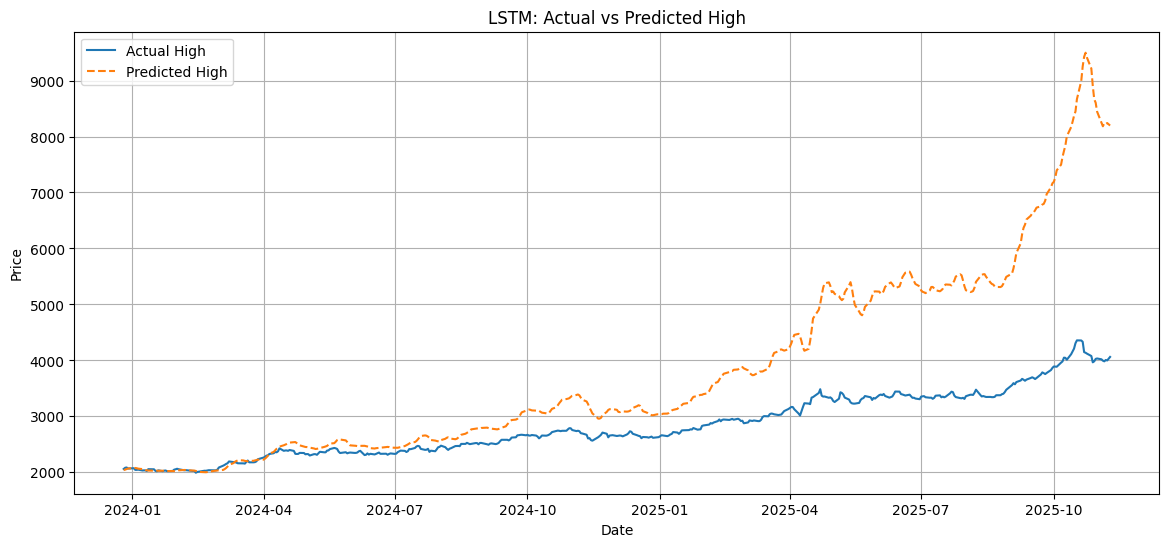

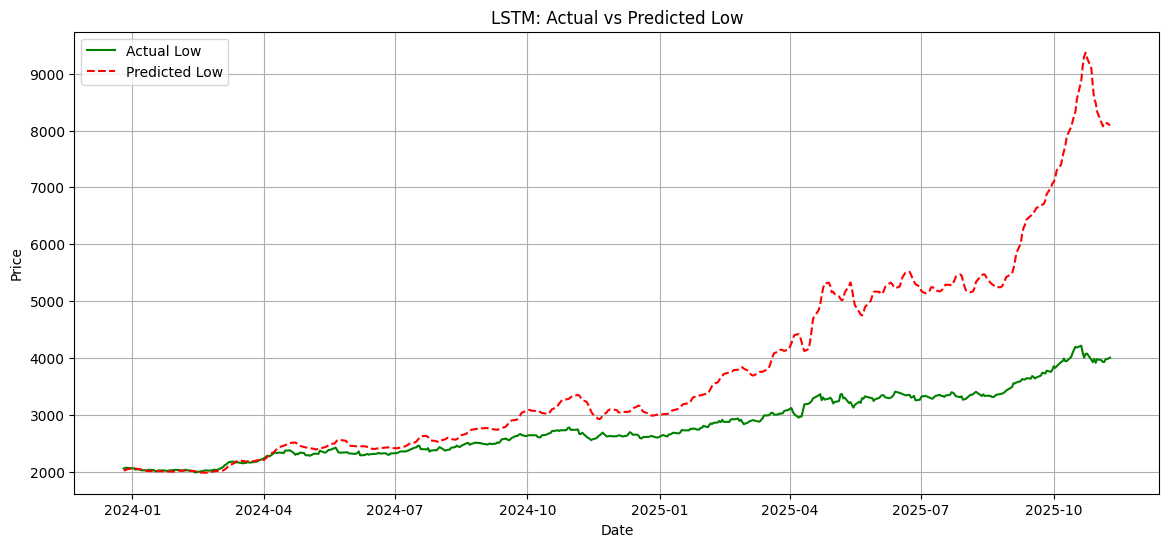

In [13]:
features = ['Open', 'Close', 'High', 'Low']
X = df[features].values
y_high = df['High'].values
y_low = df['Low'].values

# Scaling
scaler_X = MinMaxScaler()
X_scaled = scaler_X.fit_transform(X)

scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(df[['High','Low']].values)

# ------------------ CREATE SEQUENCES ------------------
def create_seq(X, y, seq_len=5):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)

seq_len = 5
X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

# Train-test split
split_idx = int(len(X_seq)*0.9)
X_train, X_test = X_seq[:split_idx], X_seq[split_idx:]
y_train, y_test = y_seq[:split_idx], y_seq[split_idx:]

# Corresponding dates for test set
test_dates = df['Date'].values[seq_len + split_idx:]

# ------------------ LSTM MODEL ------------------
model = Sequential([
    LSTM(50, activation='relu', input_shape=(seq_len, X_train.shape[2]), return_sequences=False),
    Dropout(0.2),
    Dense(2)  # Predict High and Low
])
model.compile(optimizer='adam', loss='mse')

# Train
history = model.fit(
    X_train, y_train,
    epochs=25, batch_size=16,
    validation_data=(X_test, y_test),
    verbose=1
)

# ------------------ PREDICT ------------------
pred = model.predict(X_test)
pred_inv = scaler_y.inverse_transform(pred)
y_test_inv = scaler_y.inverse_transform(y_test)

pred_high, pred_low = pred_inv[:,0], pred_inv[:,1]
y_high_true, y_low_true = y_test_inv[:,0], y_test_inv[:,1]

# ------------------ METRICS ------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100
    print(f"\n📊 {label} Metrics:")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")
    print(f"MAPE : {mape:.2f}%")
    return mae, rmse, r2, mape

metrics(y_high_true, pred_high, "High (LSTM)")
metrics(y_low_true, pred_low, "Low (LSTM)")

# ------------------ PLOTS ------------------
plt.figure(figsize=(14,6))
plt.plot(test_dates, y_high_true, label="Actual High")
plt.plot(test_dates, pred_high, label="Predicted High", linestyle='--')
plt.title("LSTM: Actual vs Predicted High")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(14,6))
plt.plot(test_dates, y_low_true, label="Actual Low", color='green')
plt.plot(test_dates, pred_low, label="Predicted Low", linestyle='--', color='red')
plt.title("LSTM: Actual vs Predicted Low")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend(); plt.grid(True); plt.show()

Epoch 1/25


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


266/266 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0445 - val_loss: 4.8115
Epoch 2/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0098 - val_loss: 2.0208
Epoch 3/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0086 - val_loss: 1.3335
Epoch 4/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0078 - val_loss: 0.7451
Epoch 5/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0078 - val_loss: 0.1273
Epoch 6/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0073 - val_loss: 0.0358
Epoch 7/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0068 - val_loss: 0.0318
Epoch 8/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0068 - val_loss: 0.0328
Epoch 9/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0067 - val_loss: 0.0439
Epoch 10/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0065 - val_loss: 0.0412
Epoch 11/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0064 - val_loss: 0.2343
Epoch 12/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.

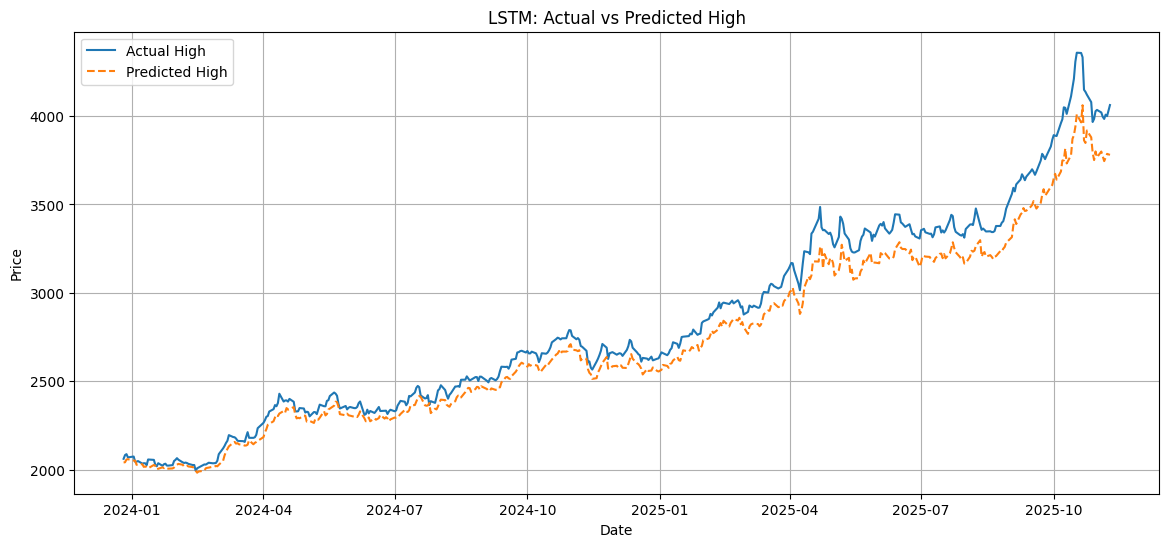

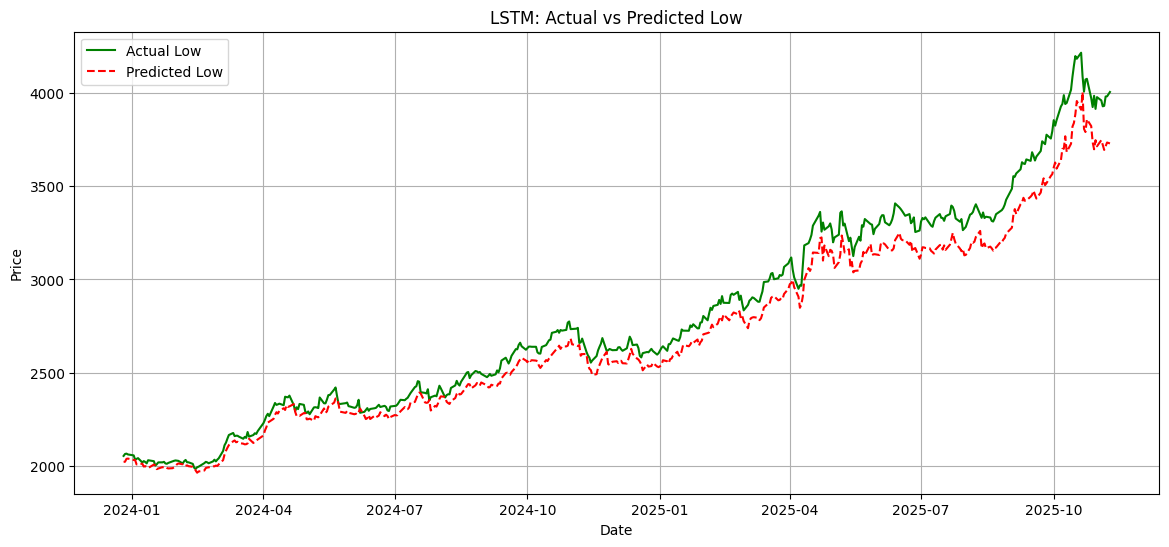

In [14]:
features = ['Open', 'Close', 'High', 'Low']
X = df[features].values
y_high = df['High'].values
y_low = df['Low'].values

# Scaling
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X)

scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(df[['High','Low']].values)

# ------------------ CREATE SEQUENCES ------------------
def create_seq(X, y, seq_len=5):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)

seq_len = 5
X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

# Train-test split
split_idx = int(len(X_seq)*0.9)
X_train, X_test = X_seq[:split_idx], X_seq[split_idx:]
y_train, y_test = y_seq[:split_idx], y_seq[split_idx:]

# Corresponding dates for test set
test_dates = df['Date'].values[seq_len + split_idx:]

# ------------------ LSTM MODEL ------------------
model = Sequential([
    LSTM(50, activation='relu', input_shape=(seq_len, X_train.shape[2]), return_sequences=False),
    Dropout(0.2),
    Dense(2)  # Predict High and Low
])
model.compile(optimizer='adam', loss='mse')

# Train
history = model.fit(
    X_train, y_train,
    epochs=25, batch_size=16,
    validation_data=(X_test, y_test),
    verbose=1
)

# ------------------ PREDICT ------------------
pred = model.predict(X_test)
pred_inv = scaler_y.inverse_transform(pred)
y_test_inv = scaler_y.inverse_transform(y_test)

pred_high, pred_low = pred_inv[:,0], pred_inv[:,1]
y_high_true, y_low_true = y_test_inv[:,0], y_test_inv[:,1]

# ------------------ METRICS ------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100
    print(f"\n📊 {label} Metrics:")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")
    print(f"MAPE : {mape:.2f}%")
    return mae, rmse, r2, mape

metrics(y_high_true, pred_high, "High (LSTM)")
metrics(y_low_true, pred_low, "Low (LSTM)")

# ------------------ PLOTS ------------------
plt.figure(figsize=(14,6))
plt.plot(test_dates, y_high_true, label="Actual High")
plt.plot(test_dates, pred_high, label="Predicted High", linestyle='--')
plt.title("LSTM: Actual vs Predicted High")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(14,6))
plt.plot(test_dates, y_low_true, label="Actual Low", color='green')
plt.plot(test_dates, pred_low, label="Predicted Low", linestyle='--', color='red')
plt.title("LSTM: Actual vs Predicted Low")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend(); plt.grid(True); plt.show()

Epoch 1/25


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


266/266 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.0501 - val_loss: 0.6507
Epoch 2/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0121 - val_loss: 0.1004
Epoch 3/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0100 - val_loss: 0.2509
Epoch 4/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0093 - val_loss: 0.0664
Epoch 5/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0089 - val_loss: 0.0424
Epoch 6/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0087 - val_loss: 0.0203
Epoch 7/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0080 - val_loss: 0.0568
Epoch 8/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0081 - val_loss: 0.0972
Epoch 9/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0070 - val_loss: 0.0403
Epoch 10/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0070 - val_loss: 0.2262
Epoch 11/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0067 - val_loss: 0.0150
Epoch 12/25
266/266 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.

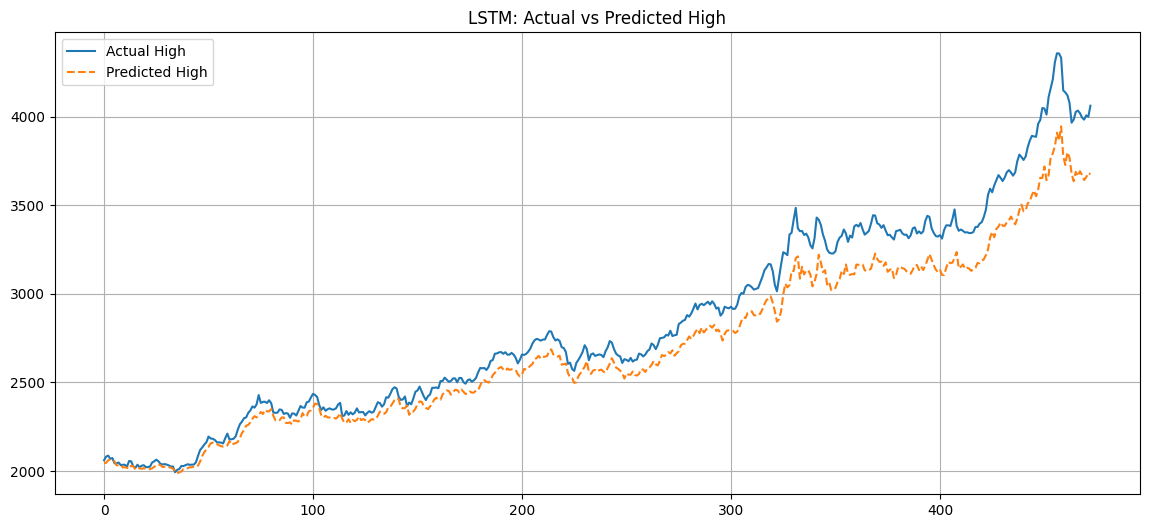

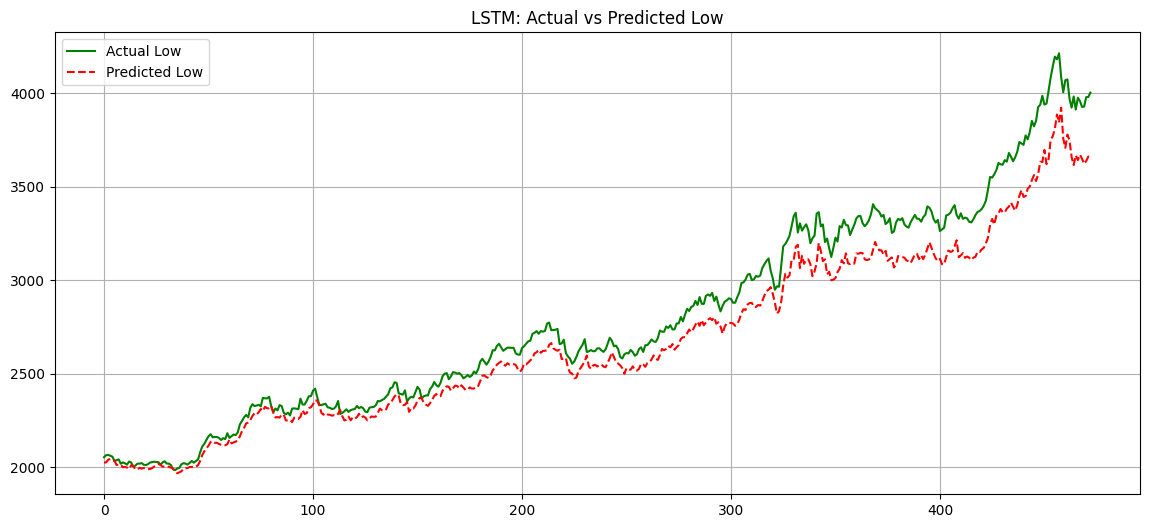

In [15]:
#for sequence length 50
features = ['Open', 'Close', 'High', 'Low']
X = df[features].values
y_high = df['High'].values
y_low = df['Low'].values

# Scaling
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X)

scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(df[['High','Low']].values)

# ------------------ CREATE SEQUENCES ------------------
def create_seq(X, y, seq_len=5):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)

seq_len = 5
X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

# Train-test split
split_idx = int(len(X_seq)*0.9)
X_train, X_test = X_seq[:split_idx], X_seq[split_idx:]
y_train, y_test = y_seq[:split_idx], y_seq[split_idx:]

# ------------------ LSTM MODEL ------------------
model = Sequential([
    LSTM(50, activation='relu', input_shape=(seq_len, X_train.shape[2]), return_sequences=False),
    Dropout(0.2),
    Dense(2)
])
model.compile(optimizer='adam', loss='mse')

# Train
history = model.fit(X_train, y_train, epochs=25, batch_size=16, validation_data=(X_test, y_test), verbose=1)

# Predict
pred = model.predict(X_test)
pred_inv = scaler_y.inverse_transform(pred)
y_test_inv = scaler_y.inverse_transform(y_test)

pred_high, pred_low = pred_inv[:,0], pred_inv[:,1]
y_high_true, y_low_true = y_test_inv[:,0], y_test_inv[:,1]

# ------------------ METRICS ------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100
    print(f"\n📊 {label} Metrics:")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")
    print(f"MAPE : {mape:.2f}%")
    return mae, rmse, r2, mape

metrics(y_high_true, pred_high, "High (LSTM)")
metrics(y_low_true, pred_low, "Low (LSTM)")

# ------------------ PLOTS ------------------
plt.figure(figsize=(14,6))
plt.plot(y_high_true, label="Actual High")
plt.plot(pred_high, label="Predicted High", linestyle='--')
plt.title("LSTM: Actual vs Predicted High")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(14,6))
plt.plot(y_low_true, label="Actual Low", color='green')
plt.plot(pred_low, label="Predicted Low", linestyle='--', color='red')
plt.title("LSTM: Actual vs Predicted Low")
plt.legend(); plt.grid(True); plt.show()

In [16]:
from tcn import TCN

d:\Anacondaa\envs\tfenv\lib\site-packages\tcn\tcn.py:268: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(TCN, self).__init__(**kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ tcn (TCN)                       │ (None, 64)             │        87,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 50)             │         3,250 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 2)              │           102 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 90,968 (355.34 KB)

 Trainable params: 90,968 (355.34 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
264/264 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - loss: 0.8072 - val_loss: 0.0547
Epoch 2/30
264/264 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0751 - val_loss: 0.1920
Epoch 3/30
264/264 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0518 - val_loss: 0.4548
Epoch 4/30
264/264 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0410 - val_loss: 0.1333
Epoch 5/30
264/264 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0341 - val_loss: 0.1359
Epoch 6/30
264/264 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0292 - val_loss: 0.1080
Epoch 7/30
264/264 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0252 - val_loss: 0.3042
Epoch 8/30
264/264 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0245 - val_loss: 0.1746
Epoch 9/30
264/264 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0217 - val_loss: 0.1283
Epoch 10/30
264/264 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0222 - val_loss: 0.0446
Epoch 11/30
264/264 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0207 - val_loss: 0.0320
Epoch 12/30
264/264 ━━━━━━━━━━━━━━━━━━━━ 

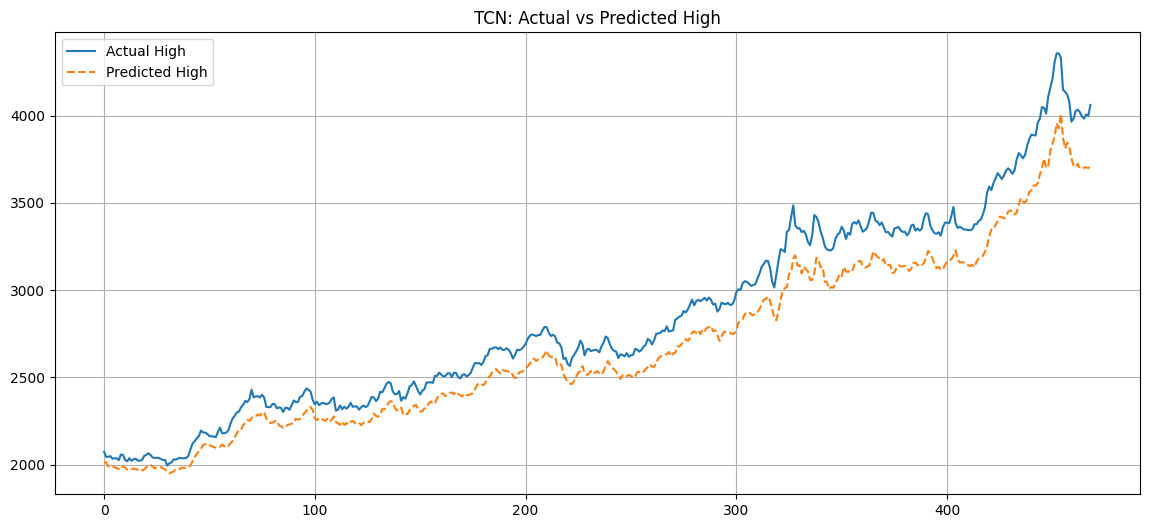

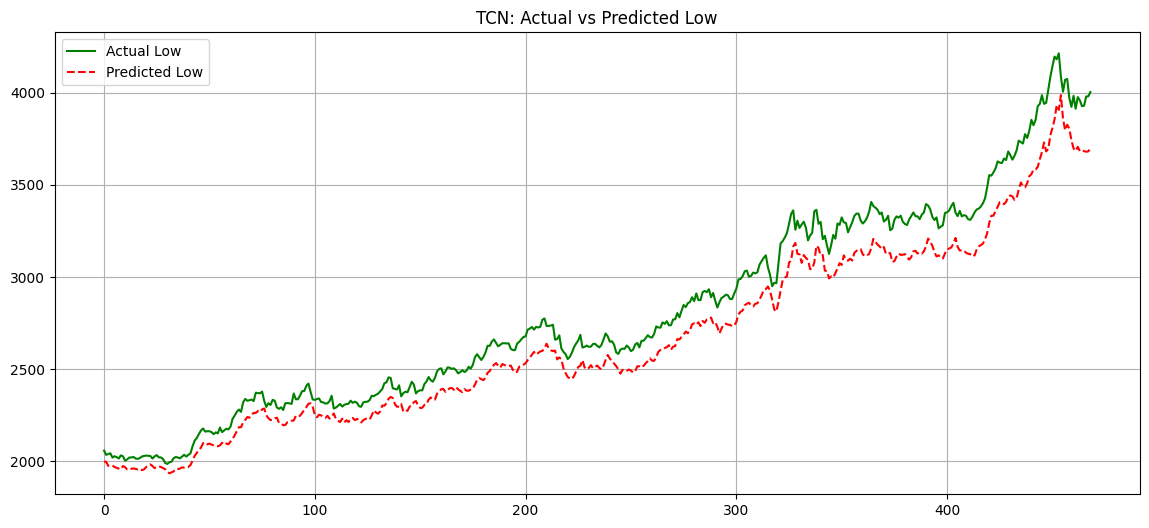

In [17]:





features = ['Open', 'Close', 'High', 'Low']
X = df[features].values
y = df[['High','Low']].values

# ------------------ SCALING ------------------
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X)

scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(y)

# ------------------ CREATE SEQUENCES ------------------
def create_sequences(X, y, seq_len=50):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)

seq_len = 50  # Hyperparameter: sequence length
X_seq, y_seq = create_sequences(X_scaled, y_scaled, seq_len)

# Train-test split
split_idx = int(len(X_seq)*0.9)
X_train, X_test = X_seq[:split_idx], X_seq[split_idx:]
y_train, y_test = y_seq[:split_idx], y_seq[split_idx:]

# ------------------ BUILD TCN MODEL ------------------
model = Sequential([
    TCN(input_shape=(seq_len, X_train.shape[2]), 
        nb_filters=64,       # Number of convolutional filters
        kernel_size=3,       # Filter/kernel size
        dilations=[1,2,4,8],# Dilation factors for receptive field
        dropout_rate=0.2,    # Dropout for regularization
        return_sequences=False),
    Dense(50, activation='relu'),
    Dropout(0.2),
    Dense(2)  # Predict High and Low
])

model.compile(optimizer='adam', loss='mse')
model.summary()

# ------------------ TRAIN ------------------
history = model.fit(
    X_train, y_train,
    epochs=30, batch_size=16,
    validation_data=(X_test, y_test),
    verbose=1
)

# ------------------ PREDICT ------------------
y_pred_scaled = model.predict(X_test)
y_pred = scaler_y.inverse_transform(y_pred_scaled)
y_test_inv = scaler_y.inverse_transform(y_test)

y_high_pred, y_low_pred = y_pred[:,0], y_pred[:,1]
y_high_true, y_low_true = y_test_inv[:,0], y_test_inv[:,1]

# ------------------ METRICS ------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100
    print(f"\n📊 {label} Metrics:")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")
    print(f"MAPE : {mape:.2f}%")
    return mae, rmse, r2, mape

metrics(y_high_true, y_high_pred, "High (TCN)")
metrics(y_low_true, y_low_pred, "Low (TCN)")

# ------------------ PLOTS ------------------
plt.figure(figsize=(14,6))
plt.plot(y_high_true, label="Actual High")
plt.plot(y_high_pred, label="Predicted High", linestyle='--')
plt.title("TCN: Actual vs Predicted High")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(14,6))
plt.plot(y_low_true, label="Actual Low", color='green')
plt.plot(y_low_pred, label="Predicted Low", linestyle='--', color='red')
plt.title("TCN: Actual vs Predicted Low")
plt.legend(); plt.grid(True); plt.show()


In [18]:
from sklearn.preprocessing import MinMaxScaler

d:\Anacondaa\envs\tfenv\lib\site-packages\tcn\tcn.py:268: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(TCN, self).__init__(**kwargs)


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ tcn_1 (TCN)                     │ (None, 128)            │       464,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 472,642 (1.80 MB)

 Trainable params: 472,642 (1.80 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
132/132 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step - loss: 0.6165 - val_loss: 0.0157
Epoch 2/50
132/132 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - loss: 0.0253 - val_loss: 0.0131
Epoch 3/50
132/132 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - loss: 0.0180 - val_loss: 0.0111
Epoch 4/50
132/132 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - loss: 0.0149 - val_loss: 0.0093
Epoch 5/50
132/132 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - loss: 0.0128 - val_loss: 0.0071
Epoch 6/50
132/132 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - loss: 0.0113 - val_loss: 0.0062
Epoch 7/50
132/132 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - loss: 0.0098 - val_loss: 0.0060
Epoch 8/50
132/132 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - loss: 0.0088 - val_loss: 0.0050
Epoch 9/50
132/132 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - loss: 0.0082 - val_loss: 0.0045
Epoch 10/50
132/132 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - loss: 0.0073 - val_loss: 0.0043
Epoch 11/50
132/132 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - loss: 0.0069 - val_loss: 0.0043
Epoch 12/50
132/132 ━━━━━━━━━━━━━━━━━━━━

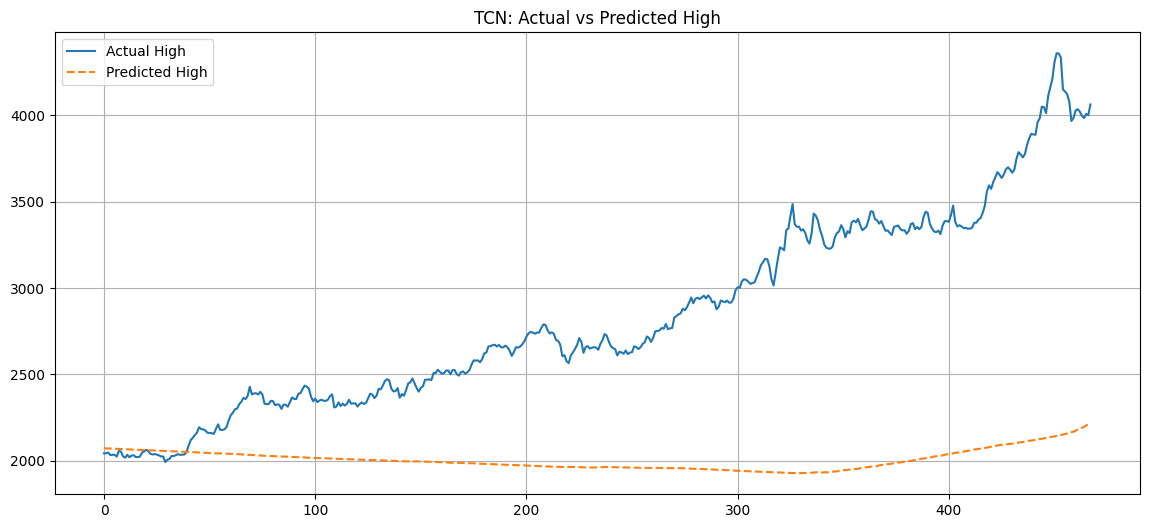

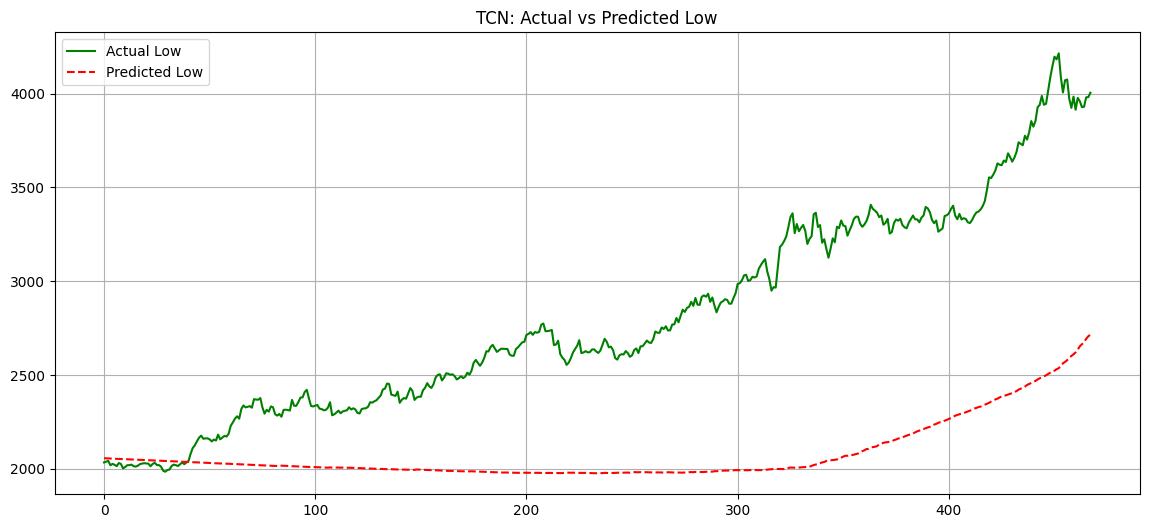

In [19]:


# Create percentage change features (returns)
df['Open_ret'] = df['Open'].pct_change()
df['High_ret'] = df['High'].pct_change()
df['Low_ret'] = df['Low'].pct_change()
df['Close_ret'] = df['Close'].pct_change()

# Drop first row (NaN due to pct_change)
df = df.dropna().reset_index(drop=True)

# Create lag features
lags = 5
for col in ['Open_ret','High_ret','Low_ret','Close_ret']:
    for lag in range(1, lags+1):
        df[f'{col}_lag{lag}'] = df[col].shift(lag)

df = df.dropna().reset_index(drop=True)

# Define features and targets
features = [c for c in df.columns if 'lag' in c]
X = df[features].values
y = df[['High_ret','Low_ret']].values  # Predict next-day returns

# ------------------ SCALING ------------------
scaler_X = MinMaxScaler()
X_scaled = scaler_X.fit_transform(X)

scaler_y = MinMaxScaler()
y_scaled = scaler_y.fit_transform(y)

# ------------------ CREATE SEQUENCES ------------------
def create_sequences(X, y, seq_len=50):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)

seq_len = 50
X_seq, y_seq = create_sequences(X_scaled, y_scaled, seq_len)

# Train-test split
split_idx = int(len(X_seq)*0.9)
X_train, X_test = X_seq[:split_idx], X_seq[split_idx:]
y_train, y_test = y_seq[:split_idx], y_seq[split_idx:]

# ------------------ BUILD TCN MODEL ------------------
model = Sequential([
    TCN(input_shape=(seq_len, X_train.shape[2]), 
        nb_filters=128,
        kernel_size=3,
        dilations=[1,2,4,8,16],
        dropout_rate=0.2,
        return_sequences=False),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(2)  # Predict High & Low returns
])

model.compile(optimizer='adam', loss='mse')
model.summary()

# ------------------ TRAIN ------------------
history = model.fit(
    X_train, y_train,
    epochs=50, batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)

# ------------------ PREDICT ------------------
y_pred_scaled = model.predict(X_test)
y_pred = scaler_y.inverse_transform(y_pred_scaled)
y_test_inv = scaler_y.inverse_transform(y_test)

# Convert predicted returns back to price
last_high = df['High'].values[split_idx + seq_len - 1]
last_low = df['Low'].values[split_idx + seq_len - 1]

y_high_pred_prices = [last_high*(1 + y_pred[0,0])]
y_low_pred_prices  = [last_low*(1 + y_pred[0,1])]

for i in range(1, len(y_pred)):
    y_high_pred_prices.append(y_high_pred_prices[-1]*(1 + y_pred[i,0]))
    y_low_pred_prices.append(y_low_pred_prices[-1]*(1 + y_pred[i,1]))

y_high_true_prices = df['High'].values[split_idx + seq_len:]
y_low_true_prices  = df['Low'].values[split_idx + seq_len:]

# ------------------ METRICS ------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100
    print(f"\n📊 {label} Metrics:")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")
    print(f"MAPE : {mape:.2f}%")
    return mae, rmse, r2, mape

metrics(y_high_true_prices, y_high_pred_prices, "High (TCN)")
metrics(y_low_true_prices, y_low_pred_prices, "Low (TCN)")

# ------------------ PLOTS ------------------
plt.figure(figsize=(14,6))
plt.plot(y_high_true_prices, label="Actual High")
plt.plot(y_high_pred_prices, label="Predicted High", linestyle='--')
plt.title("TCN: Actual vs Predicted High")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(14,6))
plt.plot(y_low_true_prices, label="Actual Low", color='green')
plt.plot(y_low_pred_prices, label="Predicted Low", linestyle='--', color='red')
plt.title("TCN: Actual vs Predicted Low")
plt.legend(); plt.grid(True); plt.show()


In [22]:
from arch import arch_model

# Calculate returns
df['Returns'] = df['Close'].pct_change().dropna()

# Fit GARCH(1,1)
model = arch_model(df['Returns'].dropna(), vol='Garch', p=1, q=1)
res = model.fit(update_freq=5)
print(res.summary())

# Forecast next 5 days volatility
forecast = res.forecast(horizon=5)
print("\nForecasted Volatility:")
print(forecast.variance.iloc[-1])


Iteration:      5,   Func. Count:     58,   Neg. LLF: 139643481977.6771
Inequality constraints incompatible    (Exit mode 4)
            Current function value: 15675.292575950556
            Iterations: 12
            Function evaluations: 116
            Gradient evaluations: 9
                     Constant Mean - GARCH Model Results                      
Dep. Variable:                Returns   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -15675.3
Distribution:                  Normal   AIC:                           31358.6
Method:            Maximum Likelihood   BIC:                           31384.4
                                        No. Observations:                 4727
Date:                Mon, Nov 10 2025   Df Residuals:                     4726
Time:                        09:42:44   Df Model:                            1
        

d:\Anacondaa\envs\tfenv\lib\site-packages\arch\univariate\base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 0.0001252. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 100 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)
C:\Users\ASUS\AppData\Local\Temp\ipykernel_20416\17756081.py:8: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  res = model.fit(update_freq=5)


In [ ]:
special_chars = """!"#$%&'()*+,-./:;<=>?@[\\]^_`{|}~"""
def create_special_encrypt_dict(k):
    encrypt_dict = {}
    for i in range(len(special_chars)):
        encrypt_dict[special_chars[i]] = special_chars[
            (i + k) % len(special_chars)
        ]
    return encrypt_dict
def create_special_decrypt_dict(k):
    decrypt_dict = {}
    for i in range(len(special_chars)):
        decrypt_dict[special_chars[i]] = special_chars[
            (i - k) % len(special_chars)
        ]
    return decrypt_dict
def caesar_encrypt(text, k=3):
    result = ""
    special_dict = create_special_encrypt_dict(k)
    for ch in text:
        if ch.isalpha():
            base = ord('A') if ch.isupper() else ord('a')
            result += chr((ord(ch) - base + k) % 26 + base)
        elif ch.isdigit():
            result += str((int(ch) + k) % 10)
        elif ch == ' ':
            continue
        elif ch in special_dict:
            result += special_dict[ch]
    return result
def caesar_decrypt(text, k=3):
    result = ""
    special_dict = create_special_decrypt_dict(k)
    for ch in text:
        if ch.isalpha():
            base = ord('A') if ch.isupper() else ord('a')
            result += chr((ord(ch) - base - k) % 26 + base)
        elif ch.isdigit():
            result += str((int(ch) - k) % 10)
        elif ch == ' ':
            continue
        elif ch in special_dict:
            result += special_dict[ch]
    return result
def mono_encrypt(text):
    clean_text = ''.join(
        ch.lower() for ch in text if ch.isalpha()
    )
    k = len(clean_text)
    shift = k % 26
    encrypted = ""
    special_dict = create_special_encrypt_dict(k)
    for ch in text:
        if ch.isalpha():
            base = ord('A') if ch.isupper() else ord('a')
            encrypted += chr(
                (ord(ch) - base + shift) % 26 + base
            )
        elif ch.isdigit():
            encrypted += str((int(ch) + k) % 10)
        elif ch == ' ':
            continue
        elif ch in special_dict:
            encrypted += special_dict[ch]
    return clean_text, k, encrypted
def mono_decrypt(text):
    clean_text = ''.join(
        ch.lower() for ch in text if ch.isalpha()
    )
    k = int(input("Enter k (length of original cleaned text): "))
    shift = k % 26
    decrypted = ""
    special_dict = create_special_decrypt_dict(k)
    for ch in text:
        if ch.isalpha():
            base = ord('A') if ch.isupper() else ord('a')
            decrypted += chr(
                (ord(ch) - base - shift) % 26 + base
            )
        elif ch.isdigit():
            decrypted += str((int(ch) - k) % 10)
        elif ch == ' ':
            continue
        elif ch in special_dict:
            decrypted += special_dict[ch]
    return clean_text, k, decrypted
while True:
    print("\n1. Caesar Cipher Encryption")
    print("2. Caesar Cipher Decryption")
    print("3. Monoalphabetic Encryption")
    print("4. Monoalphabetic Decryption")
    print("5. Exit")
    choice = input("\nEnter your choice: ")
    if choice == "1":
        text = input("Enter plaintext: ")
        encrypted = caesar_encrypt(text, 3)
        print("\nOriginal Text :", text)
        print("Key (k)       : 3")
        print("Encrypted Text:", encrypted)
    elif choice == "2":
        text = input("Enter ciphertext: ")
        decrypted = caesar_decrypt(text, 3)
        print("\nCiphertext     :", text)
        print("Key (k)        : 3")
        print("Decrypted Text :", decrypted)
    elif choice == "3":
        text = input("Enter plaintext: ")
        clean_text, k, encrypted = mono_encrypt(text)
        print("\nOriginal Text :", text)
        print("Clean Text    :", clean_text)
        print("Key (k)       :", k)
        print("Encrypted Text:", encrypted)
    elif choice == "4":
        text = input("Enter ciphertext: ")
        clean_text, k, decrypted = mono_decrypt(text)
        print("\nCiphertext     :", text)
        print("Key (k)        :", k)
        print("Decrypted Text :", decrypted)
    elif choice == "5":
        print("\nProgram terminated.")
        break
    else:
        print("\nInvalid choice! Please select 1-5.")


1. Caesar Cipher Encryption
2. Caesar Cipher Decryption
3. Monoalphabetic Encryption
4. Monoalphabetic Decryption
5. Exit

Original Text : Syed Muneer Husain Kazmi
Clean Text    : syedmuneerhusainkazmi
Key (k)       : 21
Encrypted Text: NtzyHpizzmCpnvdiFvuhd

1. Caesar Cipher Encryption
2. Caesar Cipher Decryption
3. Monoalphabetic Encryption
4. Monoalphabetic Decryption
5. Exit

Ciphertext     : syedmuneerhusainkazmi
Key (k)        : 21
Decrypted Text : xdjirzsjjwmzxfnspfern

1. Caesar Cipher Encryption
2. Caesar Cipher Decryption
3. Monoalphabetic Encryption
4. Monoalphabetic Decryption
5. Exit

Ciphertext     : NtzyHpizzmCpnvdiFvuhd
Key (k)        : 21
Decrypted Text : SyedMuneerHusainKazmi

1. Caesar Cipher Encryption
2. Caesar Cipher Decryption
3. Monoalphabetic Encryption
4. Monoalphabetic Decryption
5. Exit

Program terminated.


: 